In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

print("model v1 is working")

model v1 is working


In [2]:
from sklearn.datasets import make_classification

X, y = make_classification(
    n_samples=1000,
    n_features=8,
    n_informative=5,
    n_redundant=1,
    n_classes=2,
    random_state=42
)

df = pd.DataFrame(X, columns=[
    "feature_1",
    "feature_2",
    "feature_3",
    "feature_4",
    "feature_5",
    "feature_6",
    "feature_7",
    "feature_8"
])

df["target"] = y

df.to_csv("../data/sample_dataset.csv", index=False)

print(df.shape)
print(df.head())

(1000, 9)
   feature_1  feature_2  feature_3  feature_4  feature_5  feature_6  \
0  -0.556981  -1.536151  -2.160643  -0.576603   1.389764   0.888000   
1   1.816122  -0.408466   1.108788   1.406679  -0.503570   0.123160   
2  -3.771355  -0.227744   0.083452   1.421218  -1.244486   1.381744   
3  -1.362334  -0.035694  -0.625039   2.568234   0.498883  -0.038713   
4   1.680789   1.810320   1.368192  -1.295642  -0.566705  -1.573657   

   feature_7  feature_8  target  
0  -0.134010  -1.345210       0  
1   1.874593  -0.150614       0  
2  -0.758349   0.449827       0  
3  -2.406644  -0.342149       1  
4  -0.248126  -0.599821       1  


In [3]:
df = pd.read_csv("../data/sample_dataset.csv")

print("Dataset loaded successfully")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset loaded successfully
Shape: (1000, 9)
Columns: ['feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'target']


In [4]:
X = df.drop("target", axis=1)
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1000, 8)
Target shape: (1000,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 8)
Testing data: (200, 8)


In [6]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


In [7]:
y_pred = model.predict(X_test)

print("Predictions generated")
print(y_pred[:10])

Predictions generated
[1 0 0 1 1 0 0 1 0 1]


In [8]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.81
Precision: 0.81
Recall   : 0.81
F1 Score : 0.81


In [9]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[81 19]
 [19 81]]


In [10]:
print(y.value_counts())
print()
print(y.value_counts(normalize=True))


target
0    502
1    498
Name: count, dtype: int64

target
0    0.502
1    0.498
Name: proportion, dtype: float64


In [11]:
missing = df.isnull().sum()

print(missing)

feature_1    0
feature_2    0
feature_3    0
feature_4    0
feature_5    0
feature_6    0
feature_7    0
feature_8    0
target       0
dtype: int64


In [12]:
duplicates = df.duplicated().sum()

print("Duplicate rows:", duplicates)

Duplicate rows: 0


In [13]:
print(df.dtypes)

feature_1    float64
feature_2    float64
feature_3    float64
feature_4    float64
feature_5    float64
feature_6    float64
feature_7    float64
feature_8    float64
target         int64
dtype: object


In [14]:
print(df.describe())

         feature_1    feature_2    feature_3    feature_4    feature_5  \
count  1000.000000  1000.000000  1000.000000  1000.000000  1000.000000   
mean     -0.011035    -0.492447     0.480472     0.469059    -0.017761   
std       1.618548     1.518933     1.583809     1.489777     1.029920   
min      -5.814203    -4.258034    -4.661168    -3.889284    -2.833030   
25%      -1.132212    -1.504082    -0.542215    -0.609955    -0.722399   
50%       0.029747    -0.760929     0.583361     0.541561    -0.059187   
75%       1.077206     0.230285     1.521656     1.447875     0.686377   
max       4.605669     5.685693     5.066061     6.036793     3.098299   

         feature_6    feature_7    feature_8       target  
count  1000.000000  1000.000000  1000.000000  1000.000000  
mean     -0.105690     0.499845    -0.051950     0.498000  
std       2.371480     1.621358     1.009917     0.500246  
min      -7.637108    -4.341477    -2.899514     0.000000  
25%      -1.715258    -0.674893  

In [15]:
constant_features = [
    col for col in X.columns
    if X[col].nunique() == 1
]

print("Constant features:", constant_features)

Constant features: []


In [16]:
near_constant_features = []

for col in X.columns:
    ratio = X[col].value_counts(normalize=True).iloc[0]
    
    if ratio >= 0.95:
        near_constant_features.append(col)

print("Near-constant features:", near_constant_features)

Near-constant features: []


In [17]:
correlation = X.corr()

print(correlation.round(2))

           feature_1  feature_2  feature_3  feature_4  feature_5  feature_6  \
feature_1       1.00       0.24       0.27      -0.23       0.01      -0.19   
feature_2       0.24       1.00       0.02      -0.30      -0.01       0.35   
feature_3       0.27       0.02       1.00       0.06       0.03      -0.72   
feature_4      -0.23      -0.30       0.06       1.00      -0.00       0.06   
feature_5       0.01      -0.01       0.03      -0.00       1.00      -0.06   
feature_6      -0.19       0.35      -0.72       0.06      -0.06       1.00   
feature_7       0.40       0.19      -0.10      -0.15      -0.06       0.58   
feature_8      -0.04      -0.02      -0.02       0.05      -0.04       0.03   

           feature_7  feature_8  
feature_1       0.40      -0.04  
feature_2       0.19      -0.02  
feature_3      -0.10      -0.02  
feature_4      -0.15       0.05  
feature_5      -0.06      -0.04  
feature_6       0.58       0.03  
feature_7       1.00       0.01  
feature_8       

In [18]:
high_correlations = []

for i in range(len(correlation.columns)):
    for j in range(i + 1, len(correlation.columns)):
        value = correlation.iloc[i, j]

        if abs(value) >= 0.8:
            high_correlations.append((
                correlation.columns[i],
                correlation.columns[j],
                round(value, 2)
            ))

print("Highly correlated feature pairs:")
print(high_correlations)

Highly correlated feature pairs:
[]


In [19]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training target distribution:
target
0    0.5025
1    0.4975
Name: proportion, dtype: float64

Testing target distribution:
target
1    0.5
0    0.5
Name: proportion, dtype: float64


In [20]:
outlier_counts = {}

for col in X.columns:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((X[col] < lower) | (X[col] > upper)).sum()

    outlier_counts[col] = count

print("Outliers per feature:")
print(outlier_counts)

Outliers per feature:
{'feature_1': np.int64(7), 'feature_2': np.int64(51), 'feature_3': np.int64(10), 'feature_4': np.int64(8), 'feature_5': np.int64(4), 'feature_6': np.int64(2), 'feature_7': np.int64(6), 'feature_8': np.int64(4)}


In [21]:
outlier_counts = {}

for col in X.columns:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((X[col] < lower) | (X[col] > upper)).sum()

    outlier_counts[col] = count

print("Outliers per feature:")
print(outlier_counts)

Outliers per feature:
{'feature_1': np.int64(7), 'feature_2': np.int64(51), 'feature_3': np.int64(10), 'feature_4': np.int64(8), 'feature_5': np.int64(4), 'feature_6': np.int64(2), 'feature_7': np.int64(6), 'feature_8': np.int64(4)}


In [22]:
class_distribution = y.value_counts(normalize=True)

minority_ratio = class_distribution.min()

if minority_ratio < 0.20:
    print("⚠️ Class imbalance detected")
    print(class_distribution)
else:
    print("✓ No significant class imbalance detected")
    print(class_distribution)

✓ No significant class imbalance detected
target
0    0.502
1    0.498
Name: proportion, dtype: float64


In [23]:
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy :", test_accuracy)
print("Difference       :", train_accuracy - test_accuracy)

Training Accuracy: 0.81625
Testing Accuracy : 0.81
Difference       : 0.006249999999999978


In [24]:
feature_variance = X.var()

low_variance_features = feature_variance[feature_variance < 0.01]

print("Low-variance features:")
print(low_variance_features)


Low-variance features:
Series([], dtype: float64)


In [25]:
diagnostics = {
    "missing_values": int(df.isnull().sum().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "constant_features": len(constant_features),
    "near_constant_features": len(near_constant_features),
    "high_correlation_pairs": len(high_correlations),
    "outlier_features": sum(count > 0 for count in outlier_counts.values()),
    "low_variance_features": len(low_variance_features)
}

for issue, value in diagnostics.items():
    print(f"{issue}: {value}")

missing_values: 0
duplicate_rows: 0
constant_features: 0
near_constant_features: 0
high_correlation_pairs: 0
outlier_features: 8
low_variance_features: 0


We use predict_prob because ROC-AUC and PR-AUC need the model's probability scores, not only the final 0/1 predictions.

In [26]:
from sklearn.metrics import roc_auc_score, average_precision_score

y_prob = model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

print("ROC-AUC:", roc_auc)
print("PR-AUC :", pr_auc)

ROC-AUC: 0.8853
PR-AUC : 0.8561476078758928


In [27]:
class_distribution = y.value_counts(normalize=True)

minority_class = class_distribution.idxmin()
minority_ratio = class_distribution.min()

imbalance_detected = minority_ratio < 0.20

print("Class distribution:")
print(class_distribution)

print("\nMinority class:", minority_class)
print("Minority ratio:", minority_ratio)
print("Imbalance detected:", imbalance_detected)

Class distribution:
target
0    0.502
1    0.498
Name: proportion, dtype: float64

Minority class: 1
Minority ratio: 0.498
Imbalance detected: False


In [28]:
import sys
sys.path.append("..")

In [29]:

from src.diagnostics import check_missing_values

missing_results = check_missing_values(df)

print("Missing value diagnosis:")
print(missing_results)

Missing value diagnosis:
{}


In [30]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

from src.diagnostics import check_duplicates

duplicate_results = check_duplicates(df)

print("Duplicate rows:", duplicate_results)

Duplicate rows: 0


In [31]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)
from src.diagnostics import check_constant_features
constant_results = check_constant_features(df, "target")
print("Constant features:", constant_results)

Constant features: []


In [32]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

from src.diagnostics import check_near_constant_features

near_constant_results = check_near_constant_features(df, "target")

print("Near-constant features:", near_constant_results)

Near-constant features: []


In [33]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

from src.diagnostics import check_high_correlations

correlation_results = check_high_correlations(df, "target")

print("High correlation pairs:", correlation_results)

High correlation pairs: []


In [34]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

from src.diagnostics import check_outliers

outlier_results = check_outliers(df, "target")

print("Outlier counts:", outlier_results)

Outlier counts: {'feature_1': 7, 'feature_2': 51, 'feature_3': 10, 'feature_4': 8, 'feature_5': 4, 'feature_6': 2, 'feature_7': 6, 'feature_8': 4}


In [35]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

from src.diagnostics import check_class_imbalance

imbalance_results = check_class_imbalance(df, "target")

print("Class imbalance:", imbalance_results)

Class imbalance: {'detected': np.False_, 'minority_class': np.int64(1), 'minority_ratio': 0.498, 'distribution': {0: 0.502, 1: 0.498}}


In [36]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)
from src.diagnostics import check_overfitting
overfitting_results = check_overfitting(
    model,
    X_train,
    y_train,
    X_test,
    y_test
)

print("Overfitting:", overfitting_results)

Overfitting: {'detected': False, 'train_accuracy': 0.8163, 'test_accuracy': 0.81, 'gap': 0.0062}


In [37]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)
from src.diagnostics import check_underfitting
underfitting_results = check_underfitting(
    model,
    X_train,
    y_train
)

print("Underfitting:", underfitting_results)

Underfitting: {'detected': False, 'train_accuracy': 0.8163}


In [38]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)
from src.diagnostics import run_diagnostics, get_diagnostic_status
diagnostic_results = run_diagnostics(
    df,
    "target",
    model,
    X_train,
    y_train,
    X_test,
    y_test
)

diagnostic_status = get_diagnostic_status(diagnostic_results)

print("Diagnostic Results:")
print(diagnostic_results)

print("\nDiagnostic Status:")
print(diagnostic_status)

Diagnostic Results:
{'missing_values': {}, 'duplicate_rows': {'count': 0, 'percentage': 0.0, 'detected': False}, 'constant_features': [], 'near_constant_features': [], 'high_correlations': [], 'outliers': {'feature_1': {'count': 7, 'percentage': 0.7, 'non_outlier_count': 993, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_2': {'count': 51, 'percentage': 5.1, 'non_outlier_count': 949, 'severity': 'high', 'reason': 'More than 5% of the values are detected as outliers.'}, 'feature_3': {'count': 10, 'percentage': 1.0, 'non_outlier_count': 990, 'severity': 'medium', 'reason': 'Between 1% and 5% of the values are detected as outliers.'}, 'feature_4': {'count': 8, 'percentage': 0.8, 'non_outlier_count': 992, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_5': {'count': 4, 'percentage': 0.4, 'non_outlier_count': 996, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}

In [39]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

from src.diagnostics import check_distribution_shift

shift_results = check_distribution_shift(
    X_train,
    X_test
)

print("Distribution shift:", shift_results)

Distribution shift: {}


In [40]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)
from src.diagnostics import run_diagnostics, get_diagnostic_status
diagnostic_results = run_diagnostics(
    df,
    "target",
    model,
    X_train,
    y_train,
    X_test,
    y_test
)
diagnostic_status = get_diagnostic_status(diagnostic_results)
print("Diagnostic Results:")
print(diagnostic_results)
print("\nDiagnostic Status:")
print(diagnostic_status)

Diagnostic Results:
{'missing_values': {}, 'duplicate_rows': {'count': 0, 'percentage': 0.0, 'detected': False}, 'constant_features': [], 'near_constant_features': [], 'high_correlations': [], 'outliers': {'feature_1': {'count': 7, 'percentage': 0.7, 'non_outlier_count': 993, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_2': {'count': 51, 'percentage': 5.1, 'non_outlier_count': 949, 'severity': 'high', 'reason': 'More than 5% of the values are detected as outliers.'}, 'feature_3': {'count': 10, 'percentage': 1.0, 'non_outlier_count': 990, 'severity': 'medium', 'reason': 'Between 1% and 5% of the values are detected as outliers.'}, 'feature_4': {'count': 8, 'percentage': 0.8, 'non_outlier_count': 992, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_5': {'count': 4, 'percentage': 0.4, 'non_outlier_count': 996, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}

In [41]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)
from src.diagnostics import check_low_variance_features
low_variance_results = check_low_variance_features(
    df,
    "target"
)
print("Low-variance features:", low_variance_results)

Low-variance features: []


In [42]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)
from src.diagnostics import run_diagnostics, get_diagnostic_status
diagnostic_results = run_diagnostics(
    df,
    "target",
    model,
    X_train,
    y_train,
    X_test,
    y_test
)
diagnostic_status = get_diagnostic_status(diagnostic_results)
print("Diagnostic Results:")
print(diagnostic_results)
print("\nDiagnostic Status:")
print(diagnostic_status)

Diagnostic Results:
{'missing_values': {}, 'duplicate_rows': {'count': 0, 'percentage': 0.0, 'detected': False}, 'constant_features': [], 'near_constant_features': [], 'high_correlations': [], 'outliers': {'feature_1': {'count': 7, 'percentage': 0.7, 'non_outlier_count': 993, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_2': {'count': 51, 'percentage': 5.1, 'non_outlier_count': 949, 'severity': 'high', 'reason': 'More than 5% of the values are detected as outliers.'}, 'feature_3': {'count': 10, 'percentage': 1.0, 'non_outlier_count': 990, 'severity': 'medium', 'reason': 'Between 1% and 5% of the values are detected as outliers.'}, 'feature_4': {'count': 8, 'percentage': 0.8, 'non_outlier_count': 992, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_5': {'count': 4, 'percentage': 0.4, 'non_outlier_count': 996, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}

In [43]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)
from src.diagnostics import check_target_leakage
leakage_results = check_target_leakage(
    df,
    "target"
)
print("Target leakage warnings:", leakage_results)

Target leakage warnings: []


In [44]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

from src.diagnostics import run_diagnostics, get_diagnostic_status
diagnostic_results = run_diagnostics(
    df,
    "target",
    model,
    X_train,
    y_train,
    X_test,
    y_test
)
diagnostic_status = get_diagnostic_status(diagnostic_results)
print("Diagnostic Results:")
print(diagnostic_results)
print("\nDiagnostic Status:")
print(diagnostic_status)

Diagnostic Results:
{'missing_values': {}, 'duplicate_rows': {'count': 0, 'percentage': 0.0, 'detected': False}, 'constant_features': [], 'near_constant_features': [], 'high_correlations': [], 'outliers': {'feature_1': {'count': 7, 'percentage': 0.7, 'non_outlier_count': 993, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_2': {'count': 51, 'percentage': 5.1, 'non_outlier_count': 949, 'severity': 'high', 'reason': 'More than 5% of the values are detected as outliers.'}, 'feature_3': {'count': 10, 'percentage': 1.0, 'non_outlier_count': 990, 'severity': 'medium', 'reason': 'Between 1% and 5% of the values are detected as outliers.'}, 'feature_4': {'count': 8, 'percentage': 0.8, 'non_outlier_count': 992, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_5': {'count': 4, 'percentage': 0.4, 'non_outlier_count': 996, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}

In [45]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)
from src.diagnostics import get_outlier_evidence
outlier_evidence = get_outlier_evidence(df, "target")
print(outlier_evidence)

{'feature_1': {'count': 7, 'percentage': 0.7, 'non_outlier_count': 993}, 'feature_2': {'count': 51, 'percentage': 5.1, 'non_outlier_count': 949}, 'feature_3': {'count': 10, 'percentage': 1.0, 'non_outlier_count': 990}, 'feature_4': {'count': 8, 'percentage': 0.8, 'non_outlier_count': 992}, 'feature_5': {'count': 4, 'percentage': 0.4, 'non_outlier_count': 996}, 'feature_6': {'count': 2, 'percentage': 0.2, 'non_outlier_count': 998}, 'feature_7': {'count': 6, 'percentage': 0.6, 'non_outlier_count': 994}, 'feature_8': {'count': 4, 'percentage': 0.4, 'non_outlier_count': 996}}


In [46]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

from src.diagnostics import run_diagnostics, get_diagnostic_status
diagnostic_results = run_diagnostics(
    df,
    "target",
    model,
    X_train,
    y_train,
    X_test,
    y_test
)

print(diagnostic_results["outliers"])

{'feature_1': {'count': 7, 'percentage': 0.7, 'non_outlier_count': 993, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_2': {'count': 51, 'percentage': 5.1, 'non_outlier_count': 949, 'severity': 'high', 'reason': 'More than 5% of the values are detected as outliers.'}, 'feature_3': {'count': 10, 'percentage': 1.0, 'non_outlier_count': 990, 'severity': 'medium', 'reason': 'Between 1% and 5% of the values are detected as outliers.'}, 'feature_4': {'count': 8, 'percentage': 0.8, 'non_outlier_count': 992, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_5': {'count': 4, 'percentage': 0.4, 'non_outlier_count': 996, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_6': {'count': 2, 'percentage': 0.2, 'non_outlier_count': 998, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_7': {'count': 6, 'percentage': 0.6, '

In [47]:
print(diagnostic_results)


{'missing_values': {}, 'duplicate_rows': {'count': 0, 'percentage': 0.0, 'detected': False}, 'constant_features': [], 'near_constant_features': [], 'high_correlations': [], 'outliers': {'feature_1': {'count': 7, 'percentage': 0.7, 'non_outlier_count': 993, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_2': {'count': 51, 'percentage': 5.1, 'non_outlier_count': 949, 'severity': 'high', 'reason': 'More than 5% of the values are detected as outliers.'}, 'feature_3': {'count': 10, 'percentage': 1.0, 'non_outlier_count': 990, 'severity': 'medium', 'reason': 'Between 1% and 5% of the values are detected as outliers.'}, 'feature_4': {'count': 8, 'percentage': 0.8, 'non_outlier_count': 992, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_5': {'count': 4, 'percentage': 0.4, 'non_outlier_count': 996, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_6': {'cou

In [48]:
import importlib
import src.diagnostics
importlib.reload(src.diagnostics)
from src.diagnostics import get_outlier_evidence, add_outlier_severity
outlier_evidence = get_outlier_evidence(df, "target")
outlier_evidence = add_outlier_severity(outlier_evidence)

print(outlier_evidence)

{'feature_1': {'count': 7, 'percentage': 0.7, 'non_outlier_count': 993, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_2': {'count': 51, 'percentage': 5.1, 'non_outlier_count': 949, 'severity': 'high', 'reason': 'More than 5% of the values are detected as outliers.'}, 'feature_3': {'count': 10, 'percentage': 1.0, 'non_outlier_count': 990, 'severity': 'medium', 'reason': 'Between 1% and 5% of the values are detected as outliers.'}, 'feature_4': {'count': 8, 'percentage': 0.8, 'non_outlier_count': 992, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_5': {'count': 4, 'percentage': 0.4, 'non_outlier_count': 996, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_6': {'count': 2, 'percentage': 0.2, 'non_outlier_count': 998, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_7': {'count': 6, 'percentage': 0.6, '

In [49]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

from src.diagnostics import run_diagnostics, get_diagnostic_status
diagnostic_results = run_diagnostics(
    df,
    "target",
    model,
    X_train,
    y_train,
    X_test,
    y_test
)

print(diagnostic_results["outliers"])

{'feature_1': {'count': 7, 'percentage': 0.7, 'non_outlier_count': 993, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_2': {'count': 51, 'percentage': 5.1, 'non_outlier_count': 949, 'severity': 'high', 'reason': 'More than 5% of the values are detected as outliers.'}, 'feature_3': {'count': 10, 'percentage': 1.0, 'non_outlier_count': 990, 'severity': 'medium', 'reason': 'Between 1% and 5% of the values are detected as outliers.'}, 'feature_4': {'count': 8, 'percentage': 0.8, 'non_outlier_count': 992, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_5': {'count': 4, 'percentage': 0.4, 'non_outlier_count': 996, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_6': {'count': 2, 'percentage': 0.2, 'non_outlier_count': 998, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_7': {'count': 6, 'percentage': 0.6, '

In [50]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)
from src.diagnostics import create_diagnostic_summary
summary = create_diagnostic_summary(diagnostic_results)

print(summary)

[{'issue': 'Outliers', 'status': 'detected', 'severity': 'high', 'evidence': {'feature_1': {'count': 7, 'percentage': 0.7, 'non_outlier_count': 993, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_2': {'count': 51, 'percentage': 5.1, 'non_outlier_count': 949, 'severity': 'high', 'reason': 'More than 5% of the values are detected as outliers.'}, 'feature_3': {'count': 10, 'percentage': 1.0, 'non_outlier_count': 990, 'severity': 'medium', 'reason': 'Between 1% and 5% of the values are detected as outliers.'}, 'feature_4': {'count': 8, 'percentage': 0.8, 'non_outlier_count': 992, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_5': {'count': 4, 'percentage': 0.4, 'non_outlier_count': 996, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_6': {'count': 2, 'percentage': 0.2, 'non_outlier_count': 998, 'severity': 'low', 'reason': 'Less than 1% of the value

In [51]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)
from src.diagnostics import get_missing_value_evidence
missing_evidence = get_missing_value_evidence(df)
print(missing_evidence)

{}


In [52]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

from src.diagnostics import run_diagnostics, get_diagnostic_status
diagnostic_results = run_diagnostics(
    df,
    "target",
    model,
    X_train,
    y_train,
    X_test,
    y_test
)

print(diagnostic_results["missing_values"])

{}


In [53]:
summary = create_diagnostic_summary(diagnostic_results)

print(summary)

[{'issue': 'Outliers', 'status': 'detected', 'severity': 'high', 'evidence': {'feature_1': {'count': 7, 'percentage': 0.7, 'non_outlier_count': 993, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_2': {'count': 51, 'percentage': 5.1, 'non_outlier_count': 949, 'severity': 'high', 'reason': 'More than 5% of the values are detected as outliers.'}, 'feature_3': {'count': 10, 'percentage': 1.0, 'non_outlier_count': 990, 'severity': 'medium', 'reason': 'Between 1% and 5% of the values are detected as outliers.'}, 'feature_4': {'count': 8, 'percentage': 0.8, 'non_outlier_count': 992, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_5': {'count': 4, 'percentage': 0.4, 'non_outlier_count': 996, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_6': {'count': 2, 'percentage': 0.2, 'non_outlier_count': 998, 'severity': 'low', 'reason': 'Less than 1% of the value

In [54]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)
from src.diagnostics import (
    get_missing_value_evidence,
    add_missing_value_severity
)
missing_evidence = get_missing_value_evidence(df)
missing_evidence = add_missing_value_severity(
    missing_evidence
)
print(missing_evidence)

{}


In [55]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

from src.diagnostics import run_diagnostics
diagnostic_results = run_diagnostics(
    df,
    "target",
    model,
    X_train,
    y_train,
    X_test,
    y_test
)

print(diagnostic_results["missing_values"])

{}


In [56]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

from src.diagnostics import create_diagnostic_summary
summary = create_diagnostic_summary(diagnostic_results)
print(summary)

[{'issue': 'Outliers', 'status': 'detected', 'severity': 'high', 'evidence': {'feature_1': {'count': 7, 'percentage': 0.7, 'non_outlier_count': 993, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_2': {'count': 51, 'percentage': 5.1, 'non_outlier_count': 949, 'severity': 'high', 'reason': 'More than 5% of the values are detected as outliers.'}, 'feature_3': {'count': 10, 'percentage': 1.0, 'non_outlier_count': 990, 'severity': 'medium', 'reason': 'Between 1% and 5% of the values are detected as outliers.'}, 'feature_4': {'count': 8, 'percentage': 0.8, 'non_outlier_count': 992, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_5': {'count': 4, 'percentage': 0.4, 'non_outlier_count': 996, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_6': {'count': 2, 'percentage': 0.2, 'non_outlier_count': 998, 'severity': 'low', 'reason': 'Less than 1% of the value

In [57]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

from src.diagnostics import get_class_imbalance_evidence

class_evidence = get_class_imbalance_evidence(df, "target")

print(class_evidence)

{'minority_class': np.int64(1), 'minority_percentage': 49.8, 'majority_class': np.int64(0), 'majority_percentage': 50.2, 'distribution': {'0': 50.2, '1': 49.8}}


In [58]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)
diagnostic_results = run_diagnostics(
    df,
    "target",
    model,
    X_train,
    y_train,
    X_test,
    y_test
)

print(diagnostic_results)

{'missing_values': {}, 'duplicate_rows': {'count': 0, 'percentage': 0.0, 'detected': False}, 'constant_features': [], 'near_constant_features': [], 'high_correlations': [], 'outliers': {'feature_1': {'count': 7, 'percentage': 0.7, 'non_outlier_count': 993, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_2': {'count': 51, 'percentage': 5.1, 'non_outlier_count': 949, 'severity': 'high', 'reason': 'More than 5% of the values are detected as outliers.'}, 'feature_3': {'count': 10, 'percentage': 1.0, 'non_outlier_count': 990, 'severity': 'medium', 'reason': 'Between 1% and 5% of the values are detected as outliers.'}, 'feature_4': {'count': 8, 'percentage': 0.8, 'non_outlier_count': 992, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_5': {'count': 4, 'percentage': 0.4, 'non_outlier_count': 996, 'severity': 'low', 'reason': 'Less than 1% of the values are detected as outliers.'}, 'feature_6': {'cou

In [59]:
import importlib
import src.diagnostics
from src.diagnostics import run_diagnostics
importlib.reload(src.diagnostics)
diagnostic_results = run_diagnostics(
    df,
    "target",
    model,
    X_train,
    y_train,
    X_test,
    y_test
)
print(diagnostic_results["class_imbalance"])

{'detected': np.False_, 'minority_class': np.int64(1), 'minority_ratio': 0.498, 'distribution': {0: 0.502, 1: 0.498}, 'evidence': {'minority_class': np.int64(1), 'minority_percentage': 49.8, 'majority_class': np.int64(0), 'majority_percentage': 50.2, 'distribution': {'0': 50.2, '1': 49.8}}}


In [60]:
summary = create_diagnostic_summary(diagnostic_results)
summary

[{'issue': 'Outliers',
  'status': 'detected',
  'severity': 'high',
  'evidence': {'feature_1': {'count': 7,
    'percentage': 0.7,
    'non_outlier_count': 993,
    'severity': 'low',
    'reason': 'Less than 1% of the values are detected as outliers.'},
   'feature_2': {'count': 51,
    'percentage': 5.1,
    'non_outlier_count': 949,
    'severity': 'high',
    'reason': 'More than 5% of the values are detected as outliers.'},
   'feature_3': {'count': 10,
    'percentage': 1.0,
    'non_outlier_count': 990,
    'severity': 'medium',
    'reason': 'Between 1% and 5% of the values are detected as outliers.'},
   'feature_4': {'count': 8,
    'percentage': 0.8,
    'non_outlier_count': 992,
    'severity': 'low',
    'reason': 'Less than 1% of the values are detected as outliers.'},
   'feature_5': {'count': 4,
    'percentage': 0.4,
    'non_outlier_count': 996,
    'severity': 'low',
    'reason': 'Less than 1% of the values are detected as outliers.'},
   'feature_6': {'count': 2,

In [61]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)
from src.diagnostics import run_diagnostics
diagnostic_results = run_diagnostics(
    df,
    "target",
    model,
    X_train,
    y_train,
    X_test,
    y_test
)
diagnostic_results["outliers"]

{'feature_1': {'count': 7,
  'percentage': 0.7,
  'non_outlier_count': 993,
  'severity': 'low',
  'reason': 'Less than 1% of the values are detected as outliers.'},
 'feature_2': {'count': 51,
  'percentage': 5.1,
  'non_outlier_count': 949,
  'severity': 'high',
  'reason': 'More than 5% of the values are detected as outliers.'},
 'feature_3': {'count': 10,
  'percentage': 1.0,
  'non_outlier_count': 990,
  'severity': 'medium',
  'reason': 'Between 1% and 5% of the values are detected as outliers.'},
 'feature_4': {'count': 8,
  'percentage': 0.8,
  'non_outlier_count': 992,
  'severity': 'low',
  'reason': 'Less than 1% of the values are detected as outliers.'},
 'feature_5': {'count': 4,
  'percentage': 0.4,
  'non_outlier_count': 996,
  'severity': 'low',
  'reason': 'Less than 1% of the values are detected as outliers.'},
 'feature_6': {'count': 2,
  'percentage': 0.2,
  'non_outlier_count': 998,
  'severity': 'low',
  'reason': 'Less than 1% of the values are detected as outlie

In [62]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)
from src.diagnostics import run_diagnostics
diagnostic_results = run_diagnostics(
    df,
    "target",
    model,
    X_train,
    y_train,
    X_test,
    y_test
)
diagnostic_results["outliers"]

{'feature_1': {'count': 7,
  'percentage': 0.7,
  'non_outlier_count': 993,
  'severity': 'low',
  'reason': 'Less than 1% of the values are detected as outliers.'},
 'feature_2': {'count': 51,
  'percentage': 5.1,
  'non_outlier_count': 949,
  'severity': 'high',
  'reason': 'More than 5% of the values are detected as outliers.'},
 'feature_3': {'count': 10,
  'percentage': 1.0,
  'non_outlier_count': 990,
  'severity': 'medium',
  'reason': 'Between 1% and 5% of the values are detected as outliers.'},
 'feature_4': {'count': 8,
  'percentage': 0.8,
  'non_outlier_count': 992,
  'severity': 'low',
  'reason': 'Less than 1% of the values are detected as outliers.'},
 'feature_5': {'count': 4,
  'percentage': 0.4,
  'non_outlier_count': 996,
  'severity': 'low',
  'reason': 'Less than 1% of the values are detected as outliers.'},
 'feature_6': {'count': 2,
  'percentage': 0.2,
  'non_outlier_count': 998,
  'severity': 'low',
  'reason': 'Less than 1% of the values are detected as outlie

In [63]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)
from src.diagnostics import get_outlier_evidence
get_outlier_evidence(df, "target")

{'feature_1': {'count': 7, 'percentage': 0.7, 'non_outlier_count': 993},
 'feature_2': {'count': 51, 'percentage': 5.1, 'non_outlier_count': 949},
 'feature_3': {'count': 10, 'percentage': 1.0, 'non_outlier_count': 990},
 'feature_4': {'count': 8, 'percentage': 0.8, 'non_outlier_count': 992},
 'feature_5': {'count': 4, 'percentage': 0.4, 'non_outlier_count': 996},
 'feature_6': {'count': 2, 'percentage': 0.2, 'non_outlier_count': 998},
 'feature_7': {'count': 6, 'percentage': 0.6, 'non_outlier_count': 994},
 'feature_8': {'count': 4, 'percentage': 0.4, 'non_outlier_count': 996}}

In [64]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

from src.diagnostics import run_diagnostics, create_diagnostic_summary
diagnostic_results = run_diagnostics(
    df,
    "target",
    model,
    X_train,
    y_train,
    X_test,
    y_test
)
diagnostic_results["outliers"]

{'feature_1': {'count': 7,
  'percentage': 0.7,
  'non_outlier_count': 993,
  'severity': 'low',
  'reason': 'Less than 1% of the values are detected as outliers.'},
 'feature_2': {'count': 51,
  'percentage': 5.1,
  'non_outlier_count': 949,
  'severity': 'high',
  'reason': 'More than 5% of the values are detected as outliers.'},
 'feature_3': {'count': 10,
  'percentage': 1.0,
  'non_outlier_count': 990,
  'severity': 'medium',
  'reason': 'Between 1% and 5% of the values are detected as outliers.'},
 'feature_4': {'count': 8,
  'percentage': 0.8,
  'non_outlier_count': 992,
  'severity': 'low',
  'reason': 'Less than 1% of the values are detected as outliers.'},
 'feature_5': {'count': 4,
  'percentage': 0.4,
  'non_outlier_count': 996,
  'severity': 'low',
  'reason': 'Less than 1% of the values are detected as outliers.'},
 'feature_6': {'count': 2,
  'percentage': 0.2,
  'non_outlier_count': 998,
  'severity': 'low',
  'reason': 'Less than 1% of the values are detected as outlie

In [65]:
summary = create_diagnostic_summary(diagnostic_results)
summary


[{'issue': 'Outliers',
  'status': 'detected',
  'severity': 'high',
  'evidence': {'feature_1': {'count': 7,
    'percentage': 0.7,
    'non_outlier_count': 993,
    'severity': 'low',
    'reason': 'Less than 1% of the values are detected as outliers.'},
   'feature_2': {'count': 51,
    'percentage': 5.1,
    'non_outlier_count': 949,
    'severity': 'high',
    'reason': 'More than 5% of the values are detected as outliers.'},
   'feature_3': {'count': 10,
    'percentage': 1.0,
    'non_outlier_count': 990,
    'severity': 'medium',
    'reason': 'Between 1% and 5% of the values are detected as outliers.'},
   'feature_4': {'count': 8,
    'percentage': 0.8,
    'non_outlier_count': 992,
    'severity': 'low',
    'reason': 'Less than 1% of the values are detected as outliers.'},
   'feature_5': {'count': 4,
    'percentage': 0.4,
    'non_outlier_count': 996,
    'severity': 'low',
    'reason': 'Less than 1% of the values are detected as outliers.'},
   'feature_6': {'count': 2,

In [66]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

from src.diagnostics import get_diagnostic_status
status = get_diagnostic_status(diagnostic_results)
status

{'missing_values': False,
 'duplicate_rows': False,
 'constant_features': False,
 'near_constant_features': False,
 'high_correlations': False,
 'outliers': True,
 'class_imbalance': False,
 'overfitting': False,
 'underfitting': False,
 'distribution_shift': False,
 'low_variance_features': False,
 'target_leakage': False}

In [67]:
diagnostic_report = {
    "status": status,
    "summary": summary
}

diagnostic_report

{'status': {'missing_values': False,
  'duplicate_rows': False,
  'constant_features': False,
  'near_constant_features': False,
  'high_correlations': False,
  'outliers': True,
  'class_imbalance': False,
  'overfitting': False,
  'underfitting': False,
  'distribution_shift': False,
  'low_variance_features': False,
  'target_leakage': False},
 'summary': [{'issue': 'Outliers',
   'status': 'detected',
   'severity': 'high',
   'evidence': {'feature_1': {'count': 7,
     'percentage': 0.7,
     'non_outlier_count': 993,
     'severity': 'low',
     'reason': 'Less than 1% of the values are detected as outliers.'},
    'feature_2': {'count': 51,
     'percentage': 5.1,
     'non_outlier_count': 949,
     'severity': 'high',
     'reason': 'More than 5% of the values are detected as outliers.'},
    'feature_3': {'count': 10,
     'percentage': 1.0,
     'non_outlier_count': 990,
     'severity': 'medium',
     'reason': 'Between 1% and 5% of the values are detected as outliers.'},
  

In [68]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

from src.diagnostics import create_diagnostic_report
diagnostic_report = create_diagnostic_report(diagnostic_results)
diagnostic_report

{'status': {'missing_values': False,
  'duplicate_rows': False,
  'constant_features': False,
  'near_constant_features': False,
  'high_correlations': False,
  'outliers': True,
  'class_imbalance': False,
  'overfitting': False,
  'underfitting': False,
  'distribution_shift': False,
  'low_variance_features': False,
  'target_leakage': False},
 'summary': [{'issue': 'Outliers',
   'status': 'detected',
   'severity': 'high',
   'evidence': {'feature_1': {'count': 7,
     'percentage': 0.7,
     'non_outlier_count': 993,
     'severity': 'low',
     'reason': 'Less than 1% of the values are detected as outliers.'},
    'feature_2': {'count': 51,
     'percentage': 5.1,
     'non_outlier_count': 949,
     'severity': 'high',
     'reason': 'More than 5% of the values are detected as outliers.'},
    'feature_3': {'count': 10,
     'percentage': 1.0,
     'non_outlier_count': 990,
     'severity': 'medium',
     'reason': 'Between 1% and 5% of the values are detected as outliers.'},
  

In [69]:
import json

with open("../data/diagnostic_report.json", "w") as file:
    json.dump(diagnostic_report, file, indent=4, default=str)

In [70]:
import json

with open("../data/diagnostic_report.json", "r") as file:
    saved_report = json.load(file)
print(saved_report["status"])

{'missing_values': False, 'duplicate_rows': False, 'constant_features': False, 'near_constant_features': False, 'high_correlations': False, 'outliers': True, 'class_imbalance': False, 'overfitting': False, 'underfitting': False, 'distribution_shift': False, 'low_variance_features': False, 'target_leakage': False}


In [71]:
import sys
sys.path.append("..")
import src.diagnostics
from src.diagnostics import cap_outliers
df_fixed = cap_outliers(df, "target")
df.head()

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,target
0,-0.556981,-1.536151,-2.160643,-0.576603,1.389764,0.888000,-0.134010,-1.345210,0
1,1.816122,-0.408466,1.108788,1.406679,-0.503570,0.123160,1.874593,-0.150614,0
2,-3.771355,-0.227744,0.083452,1.421218,-1.244486,1.381744,-0.758349,0.449827,0
3,-1.362334,-0.035694,-0.625039,2.568234,0.498883,-0.038713,-2.406644,-0.342149,1
4,1.680789,1.810320,1.368192,-1.295642,-0.566705,-1.573657,-0.248126,-0.599821,1


In [72]:
from src.diagnostics import cap_outliers

df_fixed = cap_outliers(df, "target")

df_fixed.head()

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,target
0,-0.556981,-1.536151,-2.160643,-0.576603,1.389764,0.888000,-0.134010,-1.345210,0
1,1.816122,-0.408466,1.108788,1.406679,-0.503570,0.123160,1.874593,-0.150614,0
2,-3.771355,-0.227744,0.083452,1.421218,-1.244486,1.381744,-0.758349,0.449827,0
3,-1.362334,-0.035694,-0.625039,2.568234,0.498883,-0.038713,-2.406644,-0.342149,1
4,1.680789,1.810320,1.368192,-1.295642,-0.566705,-1.573657,-0.248126,-0.599821,1


In [73]:
df["feature_2"].max(), df_fixed["feature_2"].max()


(np.float64(5.685693349562584), np.float64(2.8318353787606267))

In [74]:
fixed_diagnostics = run_diagnostics(
    df_fixed,
    "target",
    model,
    X_train,
    y_train,
    X_test,
    y_test
)
fixed_report = create_diagnostic_report(fixed_diagnostics)

fixed_report

{'status': {'missing_values': False,
  'duplicate_rows': False,
  'constant_features': False,
  'near_constant_features': False,
  'high_correlations': False,
  'outliers': False,
  'class_imbalance': False,
  'overfitting': False,
  'underfitting': False,
  'distribution_shift': False,
  'low_variance_features': False,
  'target_leakage': False},
 'summary': []}

In [75]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Original dataset
X_original = df.drop(columns=["target"])
y_original = df["target"]

X_train_original, X_test_original, y_train_original, y_test_original = train_test_split(
    X_original,
    y_original,
    test_size=0.2,
    random_state=42,
    stratify=y_original
)

# Fixed dataset
X_fixed = df_fixed.drop(columns=["target"])
y_fixed = df_fixed["target"]

X_train_fixed, X_test_fixed, y_train_fixed, y_test_fixed = train_test_split(
    X_fixed,
    y_fixed,
    test_size=0.2,
    random_state=42,
    stratify=y_fixed
)

In [76]:
# Train baseline model on original data
baseline_model = LogisticRegression(max_iter=1000)

baseline_model.fit(
    X_train_original,
    y_train_original
)

# Train model on outlier-capped data
fixed_model = LogisticRegression(max_iter=1000)

fixed_model.fit(
    X_train_fixed,
    y_train_fixed
)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [77]:
# Predictions from baseline model
baseline_predictions = baseline_model.predict(X_test_original)

# Predictions from fixed model
fixed_predictions = fixed_model.predict(X_test_fixed)

In [78]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

baseline_metrics = {
    "accuracy": accuracy_score(y_test_original, baseline_predictions),
    "precision": precision_score(y_test_original, baseline_predictions),
    "recall": recall_score(y_test_original, baseline_predictions),
    "f1_score": f1_score(y_test_original, baseline_predictions)
}

fixed_metrics = {
    "accuracy": accuracy_score(y_test_fixed, fixed_predictions),
    "precision": precision_score(y_test_fixed, fixed_predictions),
    "recall": recall_score(y_test_fixed, fixed_predictions),
    "f1_score": f1_score(y_test_fixed, fixed_predictions)
}

print("Baseline Metrics:", baseline_metrics)
print("Fixed Metrics:", fixed_metrics)

Baseline Metrics: {'accuracy': 0.81, 'precision': 0.81, 'recall': 0.81, 'f1_score': 0.81}
Fixed Metrics: {'accuracy': 0.8, 'precision': 0.8061224489795918, 'recall': 0.79, 'f1_score': 0.797979797979798}


In [79]:
import importlib
import src.diagnostics

importlib.reload(src.diagnostics)

<module 'src.diagnostics' from 'd:\\ModelLens\\notebooks\\..\\src\\diagnostics.py'>

In [80]:
from src.diagnostics import compare_model_performance
comparison = compare_model_performance(
    baseline_metrics,
    fixed_metrics
)

comparison

{'accuracy': {'before': 0.81, 'after': 0.8, 'change': -0.01},
 'precision': {'before': 0.81, 'after': 0.8061, 'change': -0.0039},
 'recall': {'before': 0.81, 'after': 0.79, 'change': -0.02},
 'f1_score': {'before': 0.81, 'after': 0.798, 'change': -0.012}}

In [81]:
import json
from datetime import datetime

experiment = {
    "experiment_name": "Outlier Capping Experiment",
    "applied_fix": "IQR Outlier Capping",
    "baseline_metrics": baseline_metrics,
    "fixed_model_metrics": fixed_metrics,
    "performance_comparison": comparison,
    "timestamp": datetime.now().isoformat()
}

with open("../data/outlier_experiment.json", "w") as file:
    json.dump(experiment, file, indent=4)

print("Experiment saved successfully!")

Experiment saved successfully!


In [82]:
from src.experiment_tracker import save_experiment

saved_experiment = save_experiment(
    experiment_name="Outlier Capping Experiment",
    applied_fix="IQR Outlier Capping",
    baseline_metrics=baseline_metrics,
    fixed_model_metrics=fixed_metrics,
    performance_comparison=comparison
)

print("Experiment saved successfully!")

Experiment saved successfully!


In [83]:
import json

with open("../data/experiments.json", "r") as file:
    experiment_history = json.load(file)

print("Total Experiments:", len(experiment_history))

print(json.dumps(experiment_history, indent=4))

Total Experiments: 2
[
    {
        "experiment_name": "Outlier Capping Experiment",
        "applied_fix": "IQR Outlier Capping",
        "baseline_metrics": {
            "accuracy": 0.81,
            "precision": 0.81,
            "recall": 0.81,
            "f1_score": 0.81
        },
        "fixed_model_metrics": {
            "accuracy": 0.8,
            "precision": 0.8061224489795918,
            "recall": 0.79,
            "f1_score": 0.797979797979798
        },
        "performance_comparison": {
            "accuracy": {
                "before": 0.81,
                "after": 0.8,
                "change": -0.01
            },
            "precision": {
                "before": 0.81,
                "after": 0.8061,
                "change": -0.0039
            },
            "recall": {
                "before": 0.81,
                "after": 0.79,
                "change": -0.02
            },
            "f1_score": {
                "before": 0.81,
                "

In [84]:
import importlib
import src.experiment_tracker
importlib.reload(src.experiment_tracker)
from src.experiment_tracker import load_experiments
experiments = load_experiments()
print("Total Experiments:", len(experiments))

for exp in experiments:
    print("Experiment:", exp["experiment_name"])
    print("Applied Fix:", exp["applied_fix"])
    print("F1 Score Before:", exp["baseline_metrics"]["f1_score"])
    print("F1 Score After:", exp["fixed_model_metrics"]["f1_score"])
    print("-" * 40)

Total Experiments: 2
Experiment: Outlier Capping Experiment
Applied Fix: IQR Outlier Capping
F1 Score Before: 0.81
F1 Score After: 0.797979797979798
----------------------------------------
Experiment: Outlier Capping Experiment
Applied Fix: IQR Outlier Capping
F1 Score Before: 0.81
F1 Score After: 0.797979797979798
----------------------------------------


In [85]:
import shap

# Use the baseline model and its training data
explainer = shap.LinearExplainer(
    baseline_model,
    X_train_original
)

# Calculate SHAP values for test data
shap_values = explainer(X_test_original)

Background dataset has 800 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=800 when initializing the masker.


In [86]:
import numpy as np
feature_importance = pd.DataFrame({
    "feature": X_test_original.columns,
    "mean_abs_shap": np.abs(shap_values.values).mean(axis=0)
})

feature_importance = feature_importance.sort_values(
    by="mean_abs_shap",
    ascending=False
)

feature_importance

,feature,mean_abs_shap
1,feature_2,1.095597
3,feature_4,0.856303
6,feature_7,0.678853
5,feature_6,0.552432
2,feature_3,0.501563
0,feature_1,0.498574
4,feature_5,0.027442
7,feature_8,0.001636


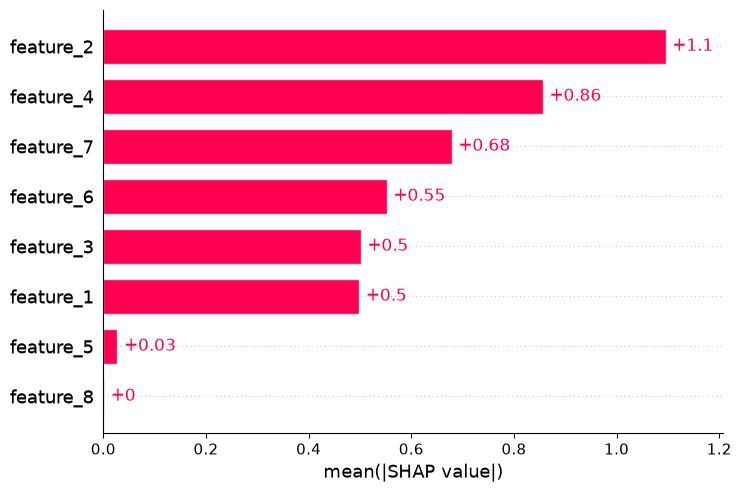

In [87]:
shap.plots.bar(shap_values)

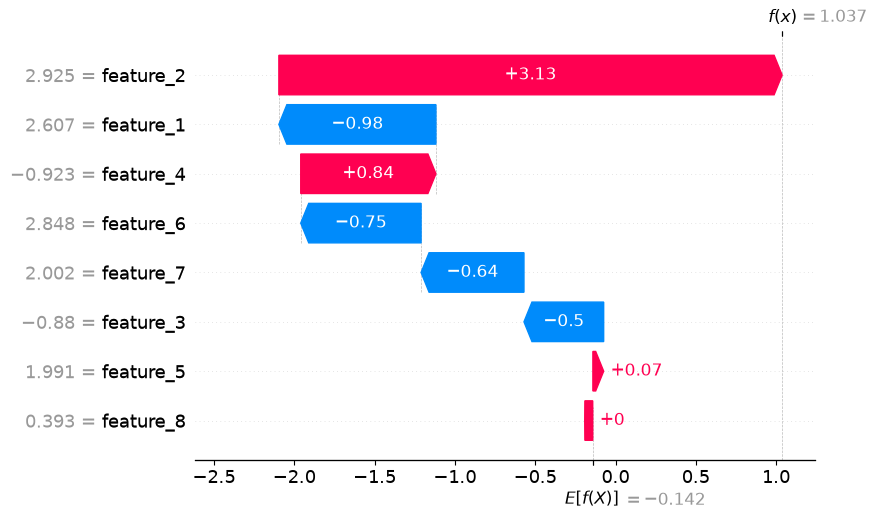

In [88]:
# Explain the first test sample
shap.plots.waterfall(shap_values[0])

In [89]:
import importlib
import src.explainability

importlib.reload(src.explainability)

from src.explainability import calculate_shap_values

shap_values_new = calculate_shap_values(
    baseline_model,
    X_train_original,
    X_test_original
)

Background dataset has 800 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=800 when initializing the masker.


In [90]:
import importlib
import src.explainability
importlib.reload(src.explainability)
from src.explainability import get_shap_summary
shap_summary = get_shap_summary(
    shap_values_new,
    X_test_original.columns
)
print(shap_summary)

{'total_features': 8, 'top_5_features': ['feature_2', 'feature_4', 'feature_7', 'feature_6', 'feature_3']}
